In [5]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import torch
import torch.nn as nn
import wfdb

from pathlib import Path
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score
from torch.utils.data import Dataset, DataLoader

In [6]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [8]:
PROJECT_ROOT = Path("..")

PTBXL_DIR = PROJECT_ROOT / "data" / "raw" / "ptb-xl"

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

MODELS_DIR = PROJECT_ROOT / "models"

REPORTS_DIR = PROJECT_ROOT / "reports"

MODELS_DIR.mkdir(parents=True, exist_ok=True)

REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("PTB-XL:", PTBXL_DIR)
print("Processed:", PROCESSED_DIR)
print("Models:", MODELS_DIR)
print("Reports:", REPORTS_DIR)

PTB-XL: ../data/raw/ptb-xl
Processed: ../data/processed
Models: ../models
Reports: ../reports


In [9]:
train_df = pd.read_csv(PROCESSED_DIR / "ptbxl_train.csv")

val_df = pd.read_csv(PROCESSED_DIR / "ptbxl_val.csv")

test_df = pd.read_csv(PROCESSED_DIR / "ptbxl_test.csv")

print("Train:", train_df.shape)

print("Validation:", val_df.shape)

print("Test:", test_df.shape)

Train: (17084, 36)
Validation: (2146, 36)
Test: (2158, 36)


/tmp/ipykernel_14124/427596917.py:1: DtypeWarning: Columns (22: electrodes_problems, 24: pacemaker) have mixed types. Specify dtype option on import or set low_memory=False.
  train_df = pd.read_csv(PROCESSED_DIR / "ptbxl_train.csv")


In [10]:
TARGET_CLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]

label_columns = [f"label_{cls}" for cls in TARGET_CLASSES]

print("Target classes:", TARGET_CLASSES)

print("Label columns:", label_columns)

Target classes: ['NORM', 'MI', 'STTC', 'CD', 'HYP']
Label columns: ['label_NORM', 'label_MI', 'label_STTC', 'label_CD', 'label_HYP']


In [11]:
missing_columns = [column for column in label_columns if column not in train_df.columns]

if missing_columns:
    raise ValueError(f"Missing target columns: {missing_columns}")

print("All target columns found.")

All target columns found.


In [12]:
print("TRAIN LABEL COUNTS")
print(train_df[label_columns].sum())

print("\nVALIDATION LABEL COUNTS")
print(val_df[label_columns].sum())

print("\nTEST LABEL COUNTS")
print(test_df[label_columns].sum())

TRAIN LABEL COUNTS
label_NORM    7596
label_MI      4379
label_STTC    4186
label_CD      3907
label_HYP     2119
dtype: int64

VALIDATION LABEL COUNTS
label_NORM    955
label_MI      540
label_STTC    528
label_CD      495
label_HYP     268
dtype: int64

TEST LABEL COUNTS
label_NORM    963
label_MI      550
label_STTC    521
label_CD      496
label_HYP     262
dtype: int64


In [13]:
def normalize_ecg(signal):
    """
    Normalize each ECG lead independently.

    Input:
        signal -> shape (samples, leads)

    Output:
        normalized signal -> same shape
    """

    mean = signal.mean(axis=0, keepdims=True)

    std = signal.std(axis=0, keepdims=True)

    std = np.where(std < 1e-8, 1.0, std)

    return (signal - mean) / std

In [14]:
class PTBXLSignalDataset(Dataset):

    def __init__(self, dataframe, base_dir, label_columns):
        self.dataframe = dataframe.reset_index(drop=True)

        self.base_dir = Path(base_dir)

        self.label_columns = label_columns

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(
        self,
        index,
    ):
        row = self.dataframe.iloc[index]

        # Read the 100 Hz ECG recording.
        record_path = self.base_dir / row["filename_lr"]

        record = wfdb.rdrecord(str(record_path))

        signal = record.p_signal.astype(np.float32)

        # Normalize each ECG lead.
        signal = normalize_ecg(signal)

        # WFDB gives:
        # (samples, leads)
        #
        # PyTorch Conv1D expects:
        # (channels, samples)
        signal = signal.T

        labels = row[self.label_columns].to_numpy(dtype=np.float32)

        return (
            torch.tensor(signal, dtype=torch.float32),
            torch.tensor(labels, dtype=torch.float32),
        )

In [15]:
train_dataset = PTBXLSignalDataset(train_df, PTBXL_DIR, label_columns)

val_dataset = PTBXLSignalDataset(val_df, PTBXL_DIR, label_columns)

test_dataset = PTBXLSignalDataset(test_df, PTBXL_DIR, label_columns)

In [16]:
print("Train samples:", len(train_dataset))

print("Validation samples:", len(val_dataset))

print("Test samples:", len(test_dataset))

Train samples: 17084
Validation samples: 2146
Test samples: 2158


In [17]:
X, y = train_dataset[0]

print("ECG shape:", X.shape)

print("Label shape:", y.shape)

print("Labels:", y.numpy())

ECG shape: torch.Size([12, 1000])
Label shape: torch.Size([5])
Labels: [1. 0. 0. 0. 0.]


In [18]:
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

In [19]:
X_batch, y_batch = next(iter(train_loader))

print("Input shape:", X_batch.shape)

print("Target shape:", y_batch.shape)

Input shape: torch.Size([64, 12, 1000])
Target shape: torch.Size([64, 5])


In [20]:
class ECGCNN(nn.Module):

    def __init__(self, num_classes=5):
        super().__init__()

        self.features = nn.Sequential(
            # Block 1
            nn.Conv1d(in_channels=12, out_channels=32, kernel_size=7, padding=3),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),
            # Block 2
            nn.Conv1d(in_channels=32, out_channels=64, kernel_size=7, padding=3),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2),
            # Block 3
            nn.Conv1d(in_channels=64, out_channels=128, kernel_size=5, padding=2),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.MaxPool1d(2),
        )

        self.classifier = nn.Sequential(
            # Reduce the time dimension.
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes),
        )

    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x

In [21]:
model = ECGCNN(num_classes=len(TARGET_CLASSES))

model = model.to(device)

print(model)

ECGCNN(
  (features): Sequential(
    (0): Conv1d(12, 32, kernel_size=(7,), stride=(1,), padding=(3,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(32, 64, kernel_size=(7,), stride=(1,), padding=(3,))
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(64, 128, kernel_size=(5,), stride=(1,), padding=(2,))
    (9): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): AdaptiveAvgPool1d(output_size=1)
    (1): Flatten(start_dim=1, end_dim=-1)
    (2): Linear(in_features=128, out_fe

In [22]:
total_parameters = sum(parameter.numel() for parameter in model.parameters())

trainable_parameters = sum(
    parameter.numel() for parameter in model.parameters() if parameter.requires_grad
)

print("Total parameters:", total_parameters)

print("Trainable parameters:", trainable_parameters)

Total parameters: 67237
Trainable parameters: 67237


In [23]:
X_batch = X_batch.to(device)

with torch.no_grad():
    output = model(X_batch)

print("Output shape:", output.shape)

Output shape: torch.Size([64, 5])


In [24]:
criterion = nn.BCEWithLogitsLoss()

In [25]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

In [26]:
NUM_EPOCHS = 15

best_val_loss = float("inf")

history = {"train_loss": [], "val_loss": []}

In [27]:
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0

    for X, y in loader:

        X = X.to(device, non_blocking=True)

        y = y.to(device, non_blocking=True)

        optimizer.zero_grad()

        logits = model(X)

        loss = criterion(logits, y)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * X.size(0)

    epoch_loss = running_loss / len(loader.dataset)

    return epoch_loss

In [28]:
def validate(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0

    with torch.no_grad():

        for X, y in loader:

            X = X.to(device, non_blocking=True)

            y = y.to(device, non_blocking=True)

            logits = model(X)

            loss = criterion(logits, y)

            running_loss += loss.item() * X.size(0)

    epoch_loss = running_loss / len(loader.dataset)

    return epoch_loss

In [29]:
for epoch in range(NUM_EPOCHS):

    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)

    val_loss = validate(model, val_loader, criterion, device)

    history["train_loss"].append(train_loss)

    history["val_loss"].append(val_loss)

    print(
        f"Epoch {epoch + 1:02d}/{NUM_EPOCHS} "
        f"| Train Loss: {train_loss:.4f} "
        f"| Val Loss: {val_loss:.4f}"
    )

    # Save the checkpoint with
    # the lowest validation loss.
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(model.state_dict(), MODELS_DIR / "ptbxl_cnn_baseline.pt")

        print("  Best model saved.")

Epoch 01/15 | Train Loss: 0.3869 | Val Loss: 0.3390
  Best model saved.
Epoch 02/15 | Train Loss: 0.3234 | Val Loss: 0.3244
  Best model saved.
Epoch 03/15 | Train Loss: 0.3087 | Val Loss: 0.3177
  Best model saved.
Epoch 04/15 | Train Loss: 0.3024 | Val Loss: 0.3212
Epoch 05/15 | Train Loss: 0.2965 | Val Loss: 0.3519
Epoch 06/15 | Train Loss: 0.2918 | Val Loss: 0.3339
Epoch 07/15 | Train Loss: 0.2881 | Val Loss: 0.3078
  Best model saved.
Epoch 08/15 | Train Loss: 0.2823 | Val Loss: 0.3124
Epoch 09/15 | Train Loss: 0.2798 | Val Loss: 0.3357
Epoch 10/15 | Train Loss: 0.2783 | Val Loss: 0.3028
  Best model saved.
Epoch 11/15 | Train Loss: 0.2769 | Val Loss: 0.3680
Epoch 12/15 | Train Loss: 0.2741 | Val Loss: 0.3095
Epoch 13/15 | Train Loss: 0.2701 | Val Loss: 0.3255
Epoch 14/15 | Train Loss: 0.2659 | Val Loss: 0.3205
Epoch 15/15 | Train Loss: 0.2662 | Val Loss: 0.3257


In [30]:
best_model_path = MODELS_DIR / "ptbxl_cnn_baseline.pt"

model.load_state_dict(
    torch.load(best_model_path, map_location=device, weights_only=True)
)

model.eval()

print("Loaded:", best_model_path)

Loaded: ../models/ptbxl_cnn_baseline.pt


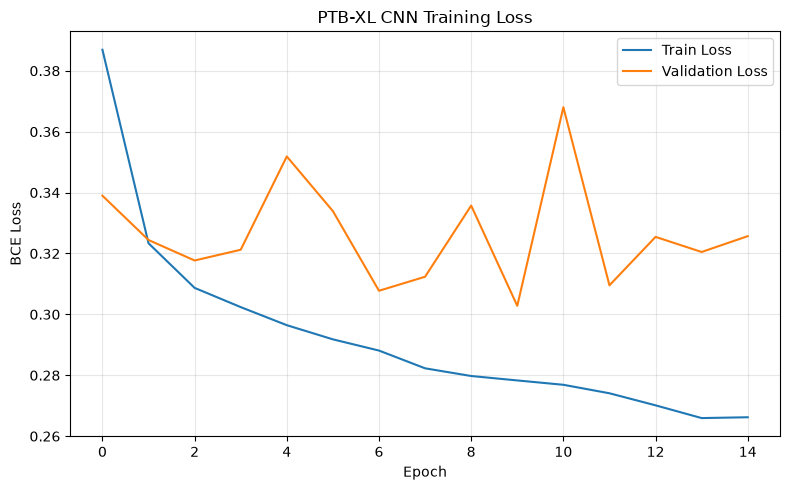

In [31]:
plt.figure(figsize=(8, 5))

plt.plot(history["train_loss"], label="Train Loss")

plt.plot(history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("BCE Loss")

plt.title("PTB-XL CNN Training Loss")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

In [32]:
history_df = pd.DataFrame(history)

history_df.to_csv(REPORTS_DIR / "ptbxl_cnn_baseline_training_history.csv", index=False)

print("Training history saved.")

Training history saved.


In [33]:
def predict(model, loader, device):

    model.eval()

    all_probabilities = []
    all_targets = []

    with torch.no_grad():

        for X, y in loader:

            X = X.to(device, non_blocking=True)

            logits = model(X)

            probabilities = torch.sigmoid(logits)

            all_probabilities.append(probabilities.cpu().numpy())

            all_targets.append(y.numpy())

    probabilities = np.concatenate(all_probabilities, axis=0)

    targets = np.concatenate(all_targets, axis=0)

    return (targets, probabilities)

In [34]:
y_test, y_test_prob = predict(model, test_loader, device)

print("Targets shape:", y_test.shape)

print("Probabilities shape:", y_test_prob.shape)

Targets shape: (2158, 5)
Probabilities shape: (2158, 5)


In [35]:
roc_auc = {}

for i, class_name in enumerate(TARGET_CLASSES):

    roc_auc[class_name] = roc_auc_score(y_test[:, i], y_test_prob[:, i])

roc_auc_df = pd.DataFrame(
    {
        "class": list(roc_auc.keys()),
        "roc_auc": list(roc_auc.values()),
    }
)

roc_auc_df

,class,roc_auc
0,NORM,0.934506
1,MI,0.914057
2,STTC,0.927053
3,CD,0.913019
4,HYP,0.818934


In [36]:
macro_roc_auc = roc_auc_score(y_test, y_test_prob, average="macro")

micro_roc_auc = roc_auc_score(y_test, y_test_prob, average="micro")

print(f"Macro ROC-AUC: " f"{macro_roc_auc:.4f}")

print(f"Micro ROC-AUC: " f"{micro_roc_auc:.4f}")

Macro ROC-AUC: 0.9015
Micro ROC-AUC: 0.9185


In [37]:
average_precision = {}

for i, class_name in enumerate(TARGET_CLASSES):

    average_precision[class_name] = average_precision_score(
        y_test[:, i], y_test_prob[:, i]
    )

average_precision_df = pd.DataFrame(
    {
        "class": list(average_precision.keys()),
        "average_precision": list(average_precision.values()),
    }
)

average_precision_df

,class,average_precision
0,NORM,0.910041
1,MI,0.797778
2,STTC,0.805714
3,CD,0.825923
4,HYP,0.469570


In [38]:
macro_ap = average_precision_score(y_test, y_test_prob, average="macro")

micro_ap = average_precision_score(y_test, y_test_prob, average="micro")

print(f"Macro Average Precision: " f"{macro_ap:.4f}")

print(f"Micro Average Precision: " f"{micro_ap:.4f}")

Macro Average Precision: 0.7618
Micro Average Precision: 0.8239


In [39]:
THRESHOLD = 0.5

y_test_pred = (y_test_prob >= THRESHOLD).astype(int)

In [40]:
macro_f1 = f1_score(y_test, y_test_pred, average="macro", zero_division=0)

micro_f1 = f1_score(y_test, y_test_pred, average="micro", zero_division=0)

print(f"Macro F1: {macro_f1:.4f}")

print(f"Micro F1: {micro_f1:.4f}")

Macro F1: 0.6470
Micro F1: 0.7326


In [41]:
class_metrics = []

for i, class_name in enumerate(TARGET_CLASSES):

    class_metrics.append(
        {
            "class": class_name,
            "roc_auc": roc_auc[class_name],
            "average_precision": (average_precision[class_name]),
            "f1": f1_score(y_test[:, i], y_test_pred[:, i], zero_division=0),
        }
    )

class_metrics = pd.DataFrame(class_metrics)

class_metrics

,class,roc_auc,average_precision,f1
0,NORM,0.934506,0.910041,0.846485
1,MI,0.914057,0.797778,0.636161
2,STTC,0.927053,0.805714,0.739394
3,CD,0.913019,0.825923,0.719553
4,HYP,0.818934,0.469570,0.293413


In [42]:
class_metrics.to_csv(REPORTS_DIR / "ptbxl_cnn_baseline_class_metrics.csv", index=False)

print("Class metrics saved.")

Class metrics saved.


In [43]:
metrics = {
    "model": "PTB-XL CNN baseline",
    "threshold": THRESHOLD,
    "macro_roc_auc": float(macro_roc_auc),
    "micro_roc_auc": float(micro_roc_auc),
    "macro_average_precision": float(macro_ap),
    "micro_average_precision": float(micro_ap),
    "macro_f1": float(macro_f1),
    "micro_f1": float(micro_f1),
}

In [44]:
with open(REPORTS_DIR / "ptbxl_cnn_baseline_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

print("Overall metrics saved.")

Overall metrics saved.


In [45]:
print("=" * 55)
print("PTB-XL CNN BASELINE RESULTS")
print("=" * 55)

print(f"Macro ROC-AUC: " f"{macro_roc_auc:.4f}")

print(f"Micro ROC-AUC: " f"{micro_roc_auc:.4f}")

print(f"Macro Average Precision: " f"{macro_ap:.4f}")

print(f"Micro Average Precision: " f"{micro_ap:.4f}")

print(f"Macro F1: " f"{macro_f1:.4f}")

print(f"Micro F1: " f"{micro_f1:.4f}")

print("\nPer-class metrics:")
print(class_metrics)

PTB-XL CNN BASELINE RESULTS
Macro ROC-AUC: 0.9015
Micro ROC-AUC: 0.9185
Macro Average Precision: 0.7618
Micro Average Precision: 0.8239
Macro F1: 0.6470
Micro F1: 0.7326

Per-class metrics:
  class   roc_auc  average_precision        f1
0  NORM  0.934506           0.910041  0.846485
1    MI  0.914057           0.797778  0.636161
2  STTC  0.927053           0.805714  0.739394
3    CD  0.913019           0.825923  0.719553
4   HYP  0.818934           0.469570  0.293413
